In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv(r"C:\Users\dell\Downloads\archive\AirPassengers.csv")

In [5]:
df.head(2)

,Month,#Passengers
0,1949-01,112
1,1949-02,118


In [6]:
df.shape

(144, 2)

In [7]:
# creating a dictionary 
# with column name and data type
data_types_dict = {'Month':object }

# we will change the data type 
# of id column to str by giving
# the dict to the astype method
df = df.astype(data_types_dict)

# checking the data types
# using df.dtypes method
df.dtypes

Month          object
#Passengers     int64
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [9]:
dates = pd.date_range(
    start='1949-01-01',
    periods=len(df),
    freq="MS"
    )

In [10]:
dates

DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[us]', length=144, freq='MS')

In [11]:
data = df['#Passengers'].to_list()

In [12]:
ts= pd.DataFrame(
    {'Passengers':data},
    index=dates
    )

In [13]:
ts

,Passengers
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390


In [14]:
import matplotlib.pyplot as plt

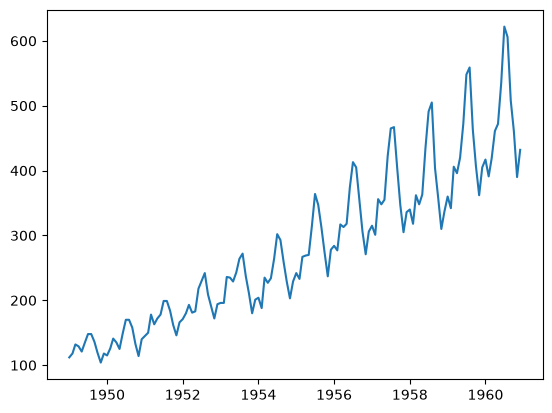

In [15]:
plt.Figure(figsize=(8,3))
plt.plot( ts.index , ts.Passengers )
plt.show()

In [16]:
!pip install statsmodels


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
from statsmodels.tsa.arima.model import ARIMA

In [18]:
train = ts[:-18]
test = ts[-18:]

In [19]:
train

,Passengers
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1959-02-01,342
1959-03-01,406
1959-04-01,396
1959-05-01,420


In [20]:
# from statsmodels.tsa.statespace.sarimax import SARIMAX

# model = SARIMAX(
    # train.Passengers,
    # order=(1,1,1),
    # seasonal_order=(1,1,1,12)
# )

# sarima_model = model.fit()

In [21]:
arima_model = ARIMA( train.Passengers , order=(1,1,12)).fit()

c:\Users\dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [22]:
arima_model

In [23]:
arima_model.summary

<bound method SARIMAXResults.summary of <statsmodels.tsa.arima.model.ARIMAResults object at 0x000002548EE0F770>>

In [24]:
y_pred = arima_model.forecast(steps=18)

In [25]:
y_pred

1959-07-01    503.535284
1959-08-01    514.384340
1959-09-01    462.915871
1959-10-01    438.911257
1959-11-01    405.477762
1959-12-01    395.574426
1960-01-01    398.324905
1960-02-01    394.075159
1960-03-01    422.410481
1960-04-01    431.492101
1960-05-01    436.892990
1960-06-01    458.186448
1960-07-01    463.699611
1960-08-01    465.127044
1960-09-01    465.496625
1960-10-01    465.592315
1960-11-01    465.617090
1960-12-01    465.623505
Freq: MS, Name: predicted_mean, dtype: float64

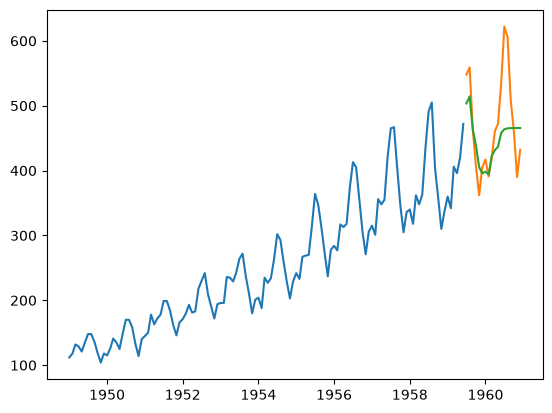

In [26]:
plt.Figure(figsize=(8,3))
plt.plot(train.index,train.Passengers)
plt.plot(test.index,test.Passengers)
plt.plot(test.index,y_pred)
plt.show()

In [27]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [28]:
sarima = SARIMAX(train, order=(1,1,1),seasonal_order=(1,1,1,12))

In [30]:
sarima_fit = sarima.fit()

c:\Users\dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [31]:
sarima_pred = sarima_fit.forecast(steps=18)

In [32]:
sarima_pred

1959-07-01    532.414133
1959-08-01    543.336334
1959-09-01    446.301176
1959-10-01    399.998187
1959-11-01    350.066936
1959-12-01    376.683454
1960-01-01    396.900766
1960-02-01    378.760178
1960-03-01    438.710344
1960-04-01    427.000286
1960-05-01    451.004896
1960-06-01    508.710671
1960-07-01    568.609344
1960-08-01    580.687533
1960-09-01    480.635201
1960-10-01    435.168202
1960-11-01    386.398126
1960-12-01    413.284657
Freq: MS, Name: predicted_mean, dtype: float64

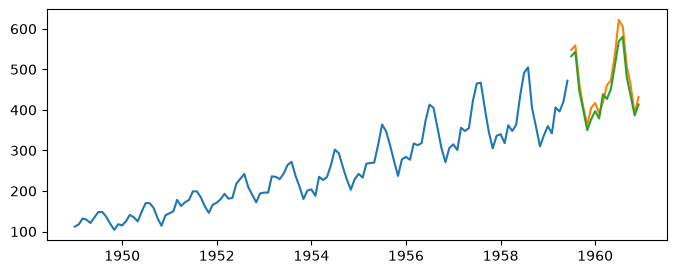

In [33]:
plt.figure(figsize=(8,3))
plt.plot(train.index , train.Passengers)
plt.plot(test.index , test.Passengers)
plt.plot(test.index , sarima_pred)
plt.show()

In [34]:
# in this plot we found july=7, and august=8 are the peak time

In [35]:
train.index.month

Index([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10,
       ...
        9, 10, 11, 12,  1,  2,  3,  4,  5,  6],
      dtype='int32', length=126)

In [36]:
train['peak_time'] = train.index.month.map(lambda val : 1 if val==7 or val==8 else 0)

In [37]:
train.head(12)

,Passengers,peak_time
1949-01-01,112,0
1949-02-01,118,0
1949-03-01,132,0
1949-04-01,129,0
1949-05-01,121,0
1949-06-01,135,0
1949-07-01,148,1
1949-08-01,148,1
1949-09-01,136,0
1949-10-01,119,0


In [44]:
test['peak_time'] = test.index.month.map(lambda val : 1 if val==7 or val==8 else 0)


In [45]:
test.head(5)

,Passengers,paek_time,peak_time
1959-07-01,548,1,1
1959-08-01,559,1,1
1959-09-01,463,0,0
1959-10-01,407,0,0
1959-11-01,362,0,0


In [46]:
sarimax = SARIMAX(train.Passengers,exog=train[['peak_time']],order=(1,1,1),seasonal_order=(1,1,1,12))

In [47]:
sarimax_fit = sarimax.fit()

c:\Users\dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [48]:
sarimax_pred = sarimax_fit.forecast(steps=18,exog=test[['peak_time']])

In [49]:
sarima_pred

1959-07-01    532.414133
1959-08-01    543.336334
1959-09-01    446.301176
1959-10-01    399.998187
1959-11-01    350.066936
1959-12-01    376.683454
1960-01-01    396.900766
1960-02-01    378.760178
1960-03-01    438.710344
1960-04-01    427.000286
1960-05-01    451.004896
1960-06-01    508.710671
1960-07-01    568.609344
1960-08-01    580.687533
1960-09-01    480.635201
1960-10-01    435.168202
1960-11-01    386.398126
1960-12-01    413.284657
Freq: MS, Name: predicted_mean, dtype: float64

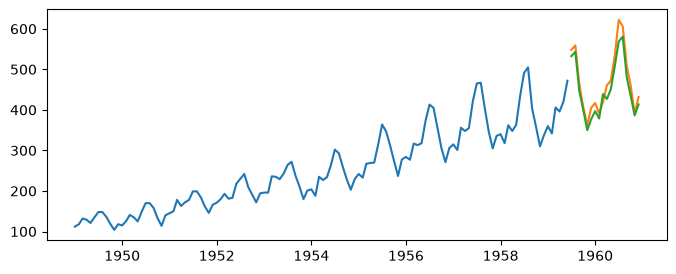

In [50]:
plt.figure(figsize=(8,3))
plt.plot(train.index , train.Passengers)
plt.plot(test.index , test.Passengers)
plt.plot(test.index , sarimax_pred)